In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [14]:
# SETTINGS
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

os.makedirs("outputs/charts", exist_ok=True)

In [15]:
# LOAD DATA

df = pd.read_csv("Global YouTube Statistics.csv", encoding="latin1")

print("Dataset Loaded Successfully")
print("Shape:", df.shape)


Dataset Loaded Successfully
Shape: (995, 28)


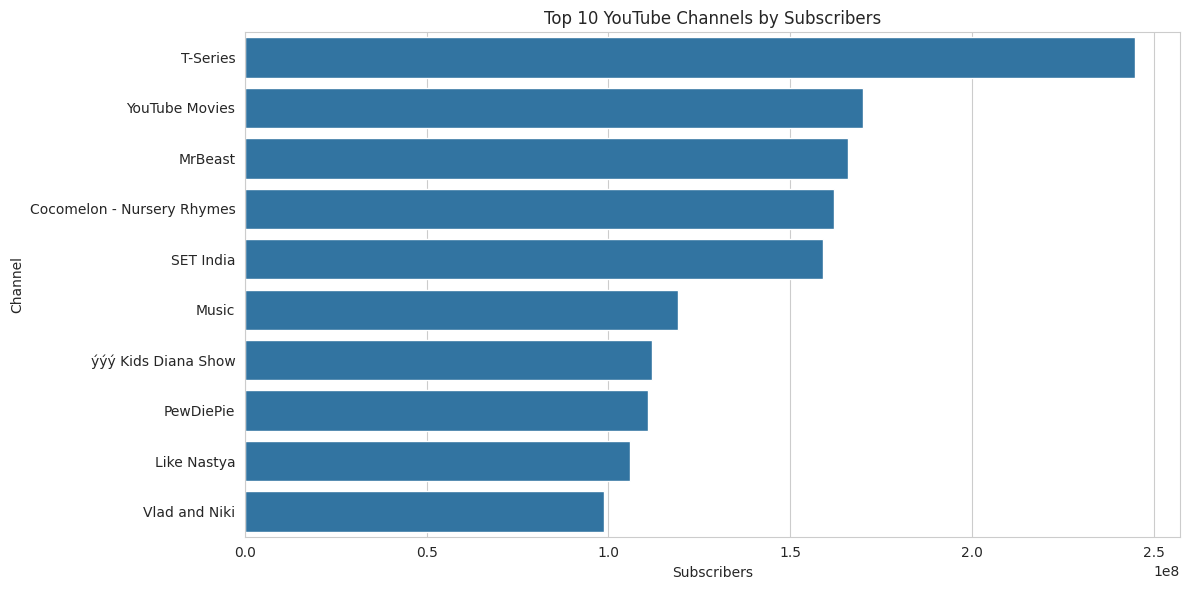

In [16]:
# 1. TOP 10 CHANNELS BY SUBSCRIBERS

top_subs = (
    df[['Youtuber', 'subscribers']]
    .sort_values(by='subscribers', ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=top_subs,
    x='subscribers',
    y='Youtuber'
)

plt.title("Top 10 YouTube Channels by Subscribers")
plt.xlabel("Subscribers")
plt.ylabel("Channel")

plt.tight_layout()
plt.savefig("outputs/charts/top_subscribers.png")
plt.show()

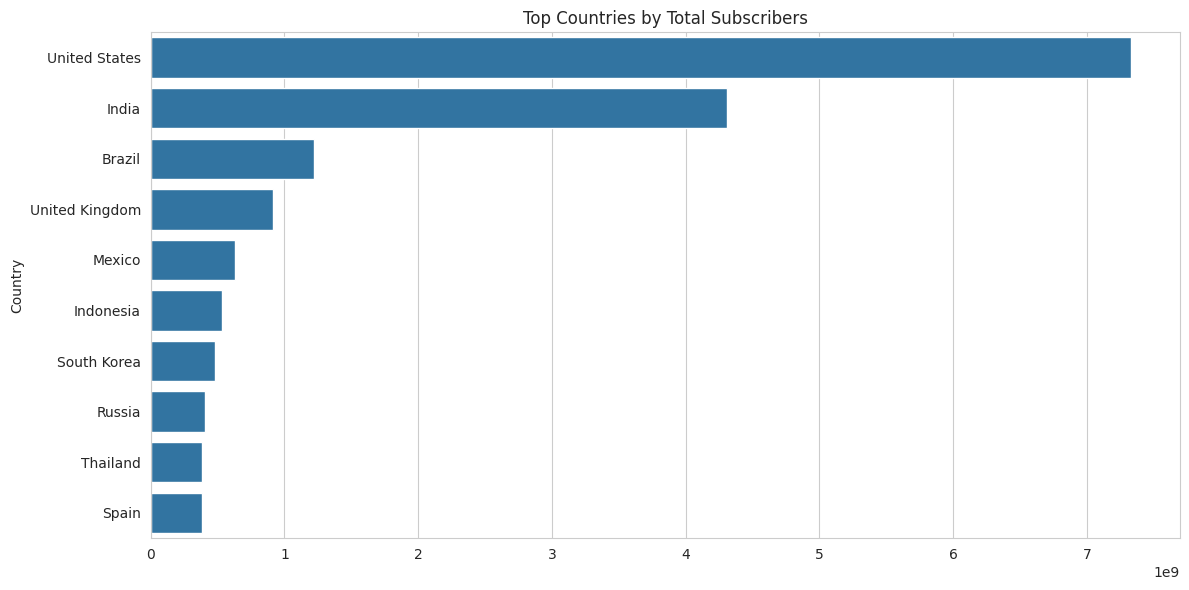

In [17]:
# 2. TOP COUNTRIES

country_subs = (
    df.groupby('Country')['subscribers']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    x=country_subs.values,
    y=country_subs.index
)

plt.title("Top Countries by Total Subscribers")

plt.tight_layout()
plt.savefig("outputs/charts/top_countries.png")
plt.show()


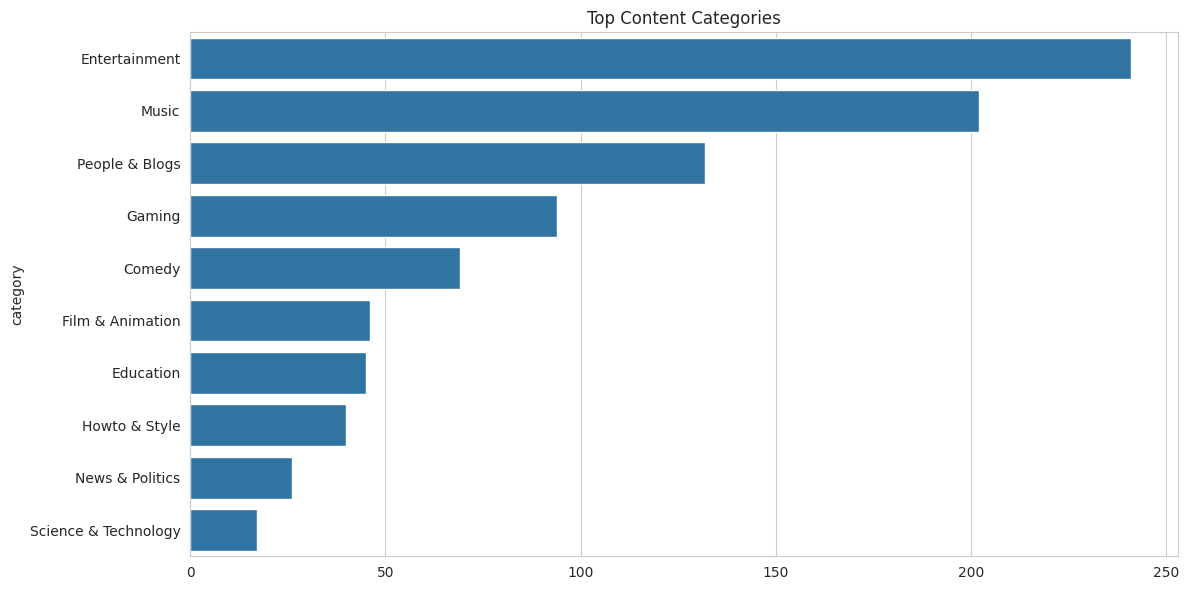

In [18]:
# 3. CATEGORY DISTRIBUTION

category_count = (
    df['category']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    x=category_count.values,
    y=category_count.index
)

plt.title("Top Content Categories")

plt.tight_layout()
plt.savefig("outputs/charts/category_distribution.png")
plt.show()


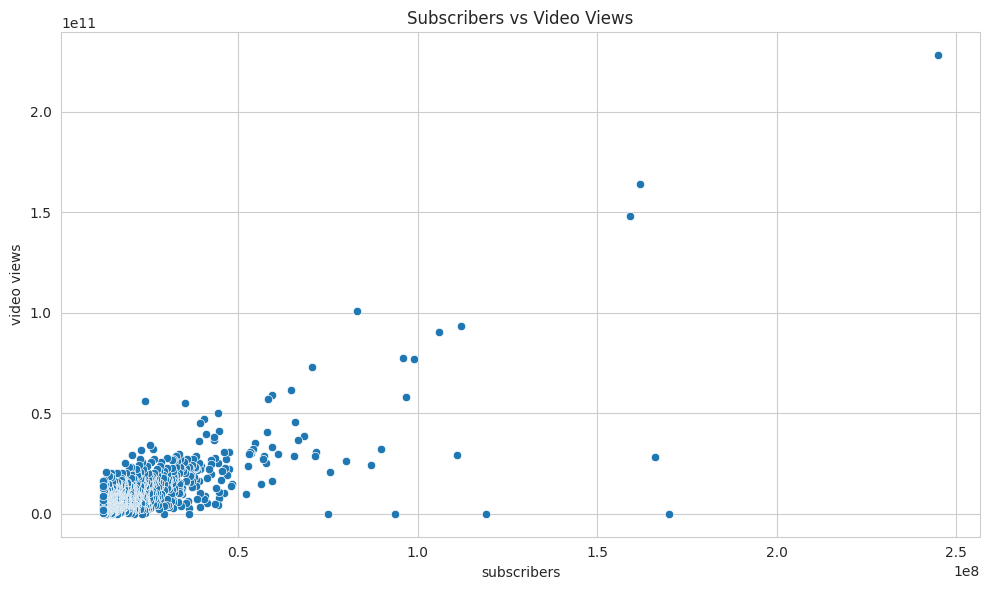

In [19]:
# 4. SUBSCRIBERS VS VIDEO VIEWS

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='subscribers',
    y='video views'
)

plt.title("Subscribers vs Video Views")

plt.tight_layout()
plt.savefig("outputs/charts/subscribers_vs_views.png")
plt.show()


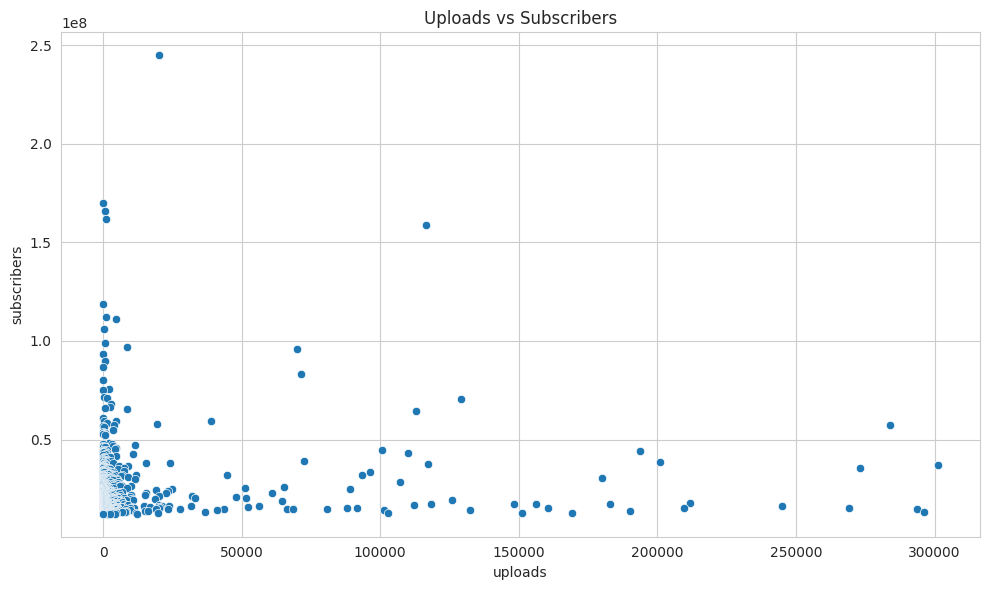

In [20]:
# 5. UPLOADS VS SUBSCRIBERS

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='uploads',
    y='subscribers'
)

plt.title("Uploads vs Subscribers")

plt.tight_layout()
plt.savefig("outputs/charts/uploads_vs_subscribers.png")
plt.show()

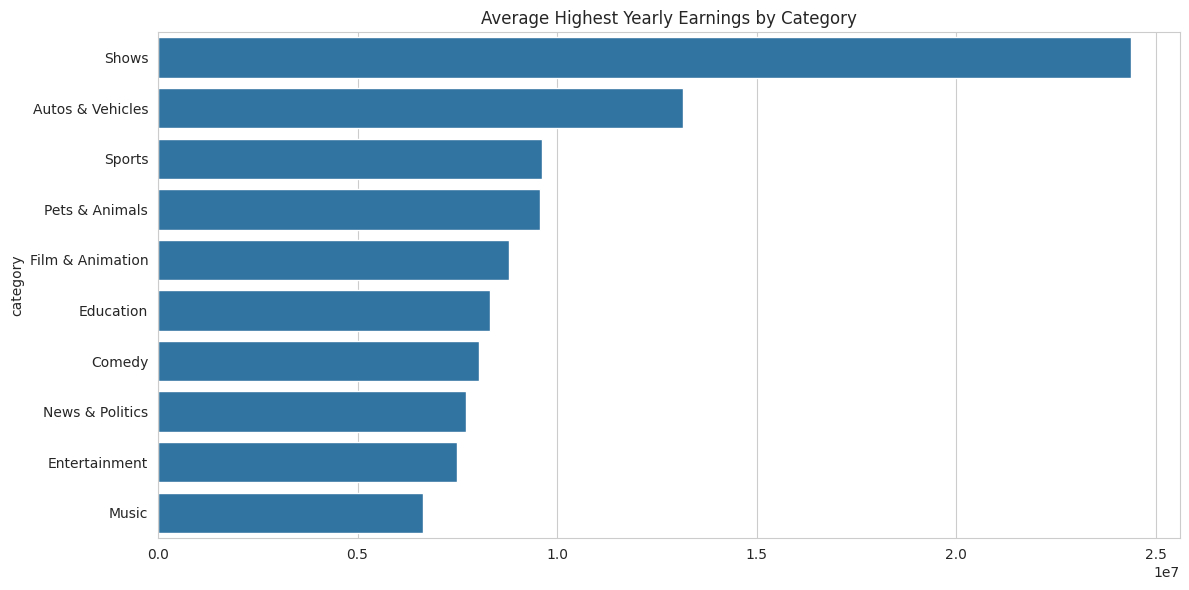

In [21]:
# 6. TOP EARNING CATEGORIES

earnings = (
    df.groupby('category')['highest_yearly_earnings']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=earnings.values,
    y=earnings.index
)

plt.title("Average Highest Yearly Earnings by Category")

plt.tight_layout()
plt.savefig("outputs/charts/top_earning_categories.png")
plt.show()

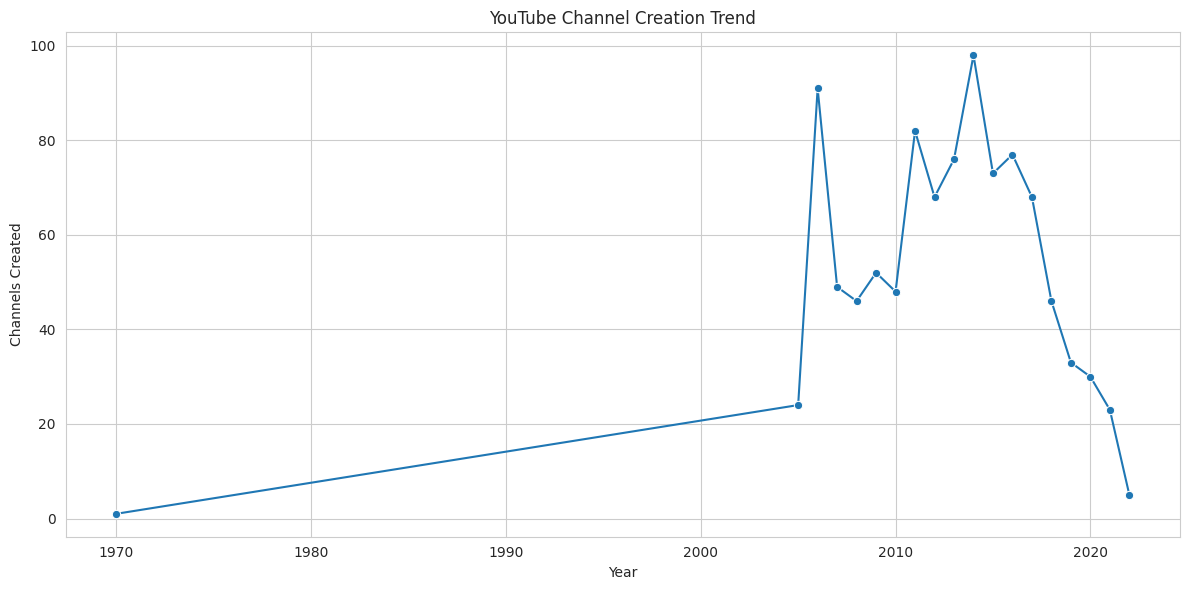

In [22]:
# 7. CHANNEL CREATION TREND

creation = (
    df['created_year']
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    x=creation.index,
    y=creation.values,
    marker="o"
)

plt.title("YouTube Channel Creation Trend")

plt.xlabel("Year")
plt.ylabel("Channels Created")

plt.tight_layout()
plt.savefig("outputs/charts/channel_creation_trend.png")
plt.show()


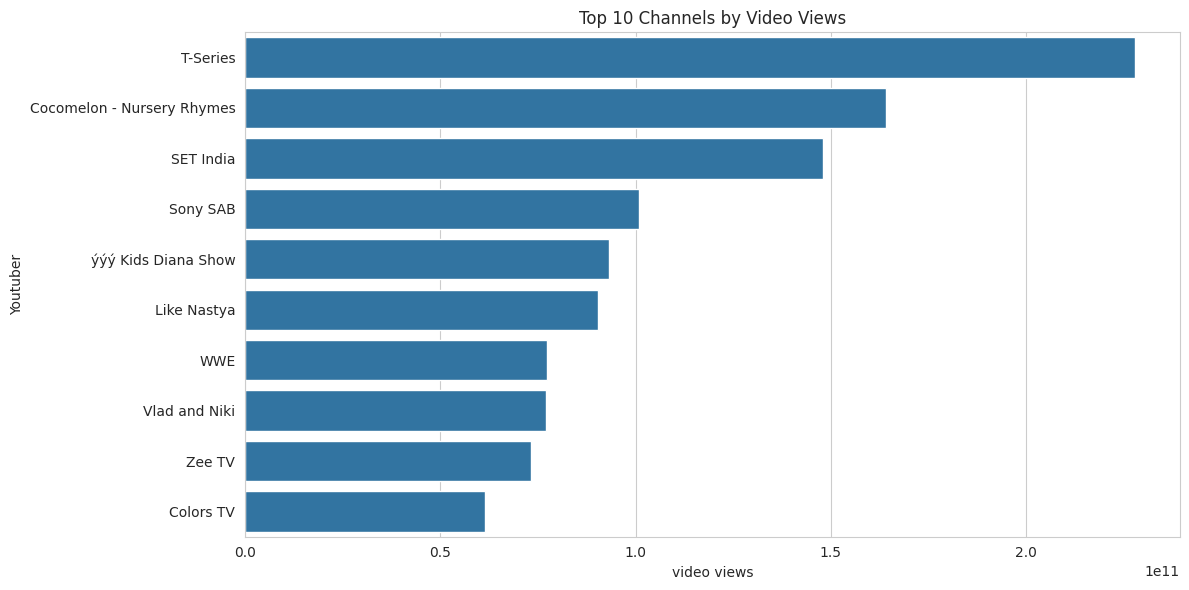

In [23]:
# 8. TOP CHANNELS BY VIDEO VIEWS

top_views = (
    df[['Youtuber', 'video views']]
    .sort_values(by='video views', ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top_views,
    x='video views',
    y='Youtuber'
)

plt.title("Top 10 Channels by Video Views")

plt.tight_layout()
plt.savefig("outputs/charts/top_views.png")
plt.show()


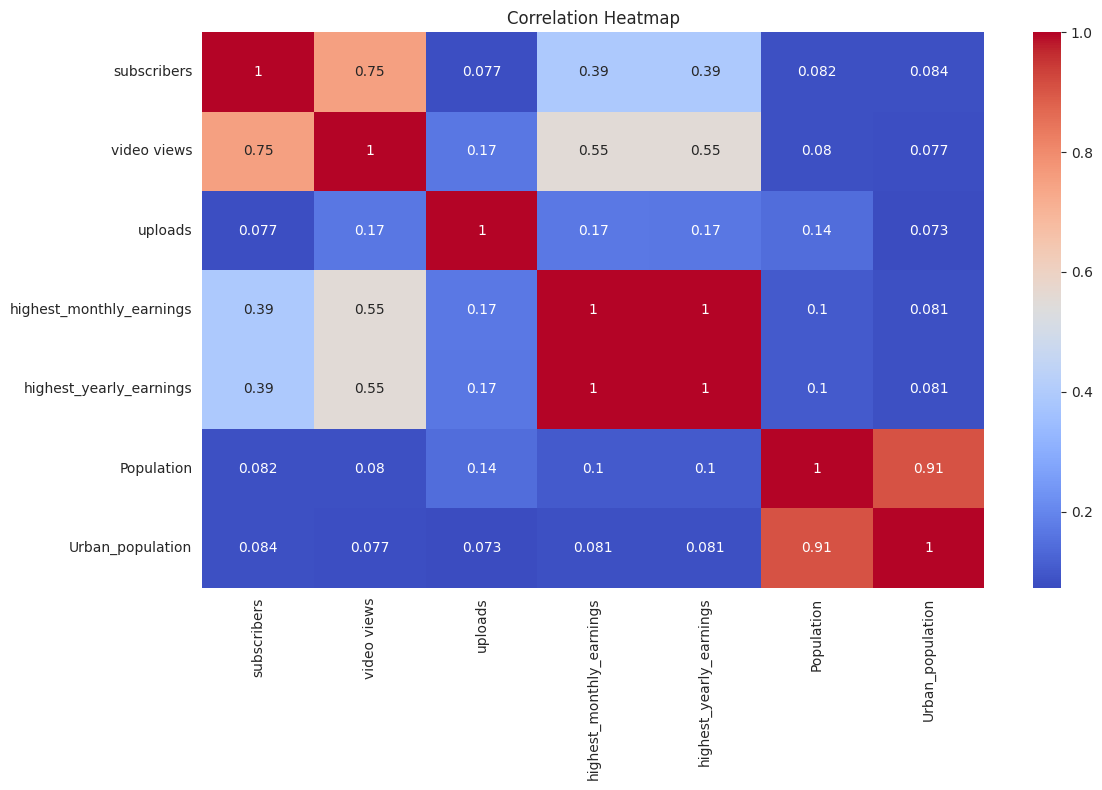

In [24]:
# 9. CORRELATION HEATMAP

numeric_cols = [
    'subscribers',
    'video views',
    'uploads',
    'highest_monthly_earnings',
    'highest_yearly_earnings',
    'Population',
    'Urban_population'
]

plt.figure(figsize=(12,8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.savefig("outputs/charts/correlation_heatmap.png")
plt.show()


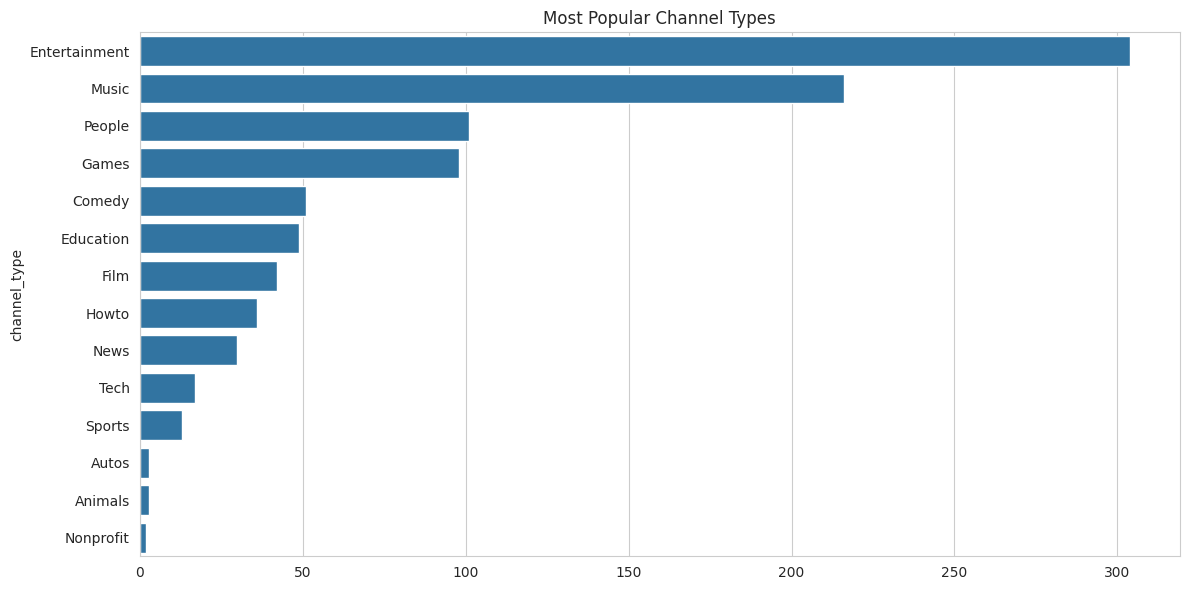


All visualizations saved successfully.


In [25]:
# 10. TOP 15 CHANNEL TYPES

channel_types = (
    df['channel_type']
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=channel_types.values,
    y=channel_types.index
)

plt.title("Most Popular Channel Types")

plt.tight_layout()
plt.savefig("outputs/charts/channel_types.png")
plt.show()

print("\nAll visualizations saved successfully.")